# Aluminium arbitrage — 03 Flows

**Question.** When the netback says a destination pays more, do the tonnes go there, how long after, and in which months do they not?

This notebook reads the trade statistics loaded in `01_data.ipynb` and the netbacks of `02_netback.ipynb`, and performs no data operation of its own. It is a check a trader can read in ten seconds, not a model: months are counted, nothing is estimated.

In [1]:
import sys
import textwrap
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, flows, netback, sql

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})
COLORS = {"midwest": "C0", "rotterdam": "C1", "japan": "C2"}
ORIGINS = list(c.ORIGINS)
DESTINATIONS = list(c.DESTINATIONS)

In [2]:
nb = netback.table()                  # the netbacks of notebook 02, by the route the rule picks
shares = flows.shares()               # each destination's share of an origin's shipments, by month
signal = flows.signal(nb)             # the destination that paid most each month, and its lead
table = flows.agreement(netbacks=nb)  # the winner against the destination whose share rose

## 1. Key findings

In [3]:
lags = (1, 2, 3)
count = pd.DataFrame({f"{k} month{'s' if k > 1 else ''} later": table.groupby("origin")[f"agree_{k}"].agg(lambda x: f"{int(x.sum())} / {x.notna().sum()}") for k in lags}).loc[ORIGINS]
rate = pd.Series({k: 100 * table[f"agree_{k}"].sum() / table[f"agree_{k}"].notna().sum() for k in lags})
count.loc["all origins, %"] = [f"{rate[k]:.0f}%" for k in lags]
print(f"{shares.index.get_level_values('period').nunique()} complete months, "
      f"{shares.index.get_level_values('period').min():%b %Y} to {shares.index.get_level_values('period').max():%b %Y}; "
      f"months in which the destination whose share rose the most is the one the netback said paid most")
count

128 complete months, Jan 2016 to Aug 2026; months in which the destination whose share rose the most is the one the netback said paid most


,1 month later,2 months later,3 months later
origin,,,
quebec,58 / 124,64 / 123,63 / 122
iceland,39 / 124,41 / 123,45 / 122
gulf,34 / 124,39 / 123,37 / 122
india,31 / 124,35 / 123,38 / 122
malaysia,52 / 124,47 / 123,49 / 122
"all origins, %",35%,37%,38%


128 complete months, January 2016 to August 2026; the netback of notebook 02, by the route the rule picks.

1. **Counted as the brief asks, the tonnes do not follow the netback month by month.** The destination whose share rose the most is the one the netback said paid most in 35% of months one month later, 37% two months later and 38% three months later, against 33% for a coin with three faces. Three months is the lag retained, by a margin too thin to mean much (section 6).
2. **In level, they do, where the origin has a choice.** Three months on, a destination takes a larger share of an origin's tonnes after the months it paid most than after the others in 12 of the 13 pairs that can be compared, mostly by one to three points. The large differences are where the netback matters: Rotterdam takes 25% of Quebec's tonnes after the months it paid most against 6% otherwise, and 74% of India's against 51% (section 6).
3. **Quebec's turn to Europe is the clearest case.** Canada's exports of unwrought aluminium to the EU-27 went from 0.2% in the first quarter of 2025 to 13% in the second and 20% in the third, the quarters the netback put Rotterdam first under the 25% duty (section 5).
4. **The tonnes ran ahead of the law.** The Gulf and India sent half their tonnes to the US in March 2025, and India again in June 2025, the months the duty went to 25% and 50%: metal landed ahead of the rise. The netback, which reads the duty in force, turned to the Midwest only in September and October 2025, once the premium had caught up.
5. **Hormuz stopped the Gulf, whatever the netback said.** Container transits at Hormuz fell under half their 2019 level in the week to 4 March 2026. The Gulf's shipments to the three destinations fell from 206 kt in March to 62 to 74 kt a month from April to July, while the Midwest kept the highest netback.
6. **Most months against the netback are explained by structure, not price.** Of the 378 months that disagree at three months, 116 belong to Quebec and Iceland, where one country takes over 90% of the tonnes year after year; 67 have a lead inside the freight band; 13 have too few tonnes to read; 182, nearly all from the Gulf, India and Malaysia, are unexplained (section 7).

The netback says where the marginal tonne should go. The statistics count every tonne, most of it under annual contracts: they move with the netback when the gap is large and lasting, a tariff regime, not with its month-to-month noise.

## 2. Method

**What is compared.** For each origin and month:

- the **signal**: the destination with the highest netback, averaged over the trade dates of the month, by the route the rule picks (notebook 02), and its lead over the second best;
- the **shipments**: the tonnes of unwrought aluminium (HS 7601) each destination declares from the origin, and each destination's share of what the origin shipped to the three.

**The agreement.** A month agrees at lag *k* if the destination whose share rose the most between that month and *k* months later is the one the netback said paid most. Three destinations: a coin with three faces agrees one month in three. The lag retained is the one that agrees most often, read in the table of section 6, not estimated.

**Mirror data.** The tonnes are the importers' declarations: US and Japanese imports from Comtrade, EU-27 imports from Comext. The Gulf is the UAE and Oman, Quebec is Canada. The EU stands for Rotterdam, the United States for the Midwest.

**Point in time.** A month of trade is used only once it is published: Comtrade's first release date, Comext's convention of 46 days (notebook 01). The agreement of month *m* at lag *k* could first be read on `available_k`, the day month *m + k* was out at all three destinations.

## 3. Data and publication lags

In [4]:
ship = flows.shipments()
coverage = ship.groupby("destination").agg(months=("period", "nunique"), first=("period", "min"), last=("period", "max"), tonnes=("tonnes", "sum"))
coverage["source"] = {"midwest": "UN Comtrade, US imports", "rotterdam": "Eurostat Comext, EU-27 imports", "japan": "UN Comtrade, Japan imports"}
coverage

,months,first,last,tonnes,source
destination,,,,,
japan,129,2016-01-01,2026-09-01,"6,482,561.5","UN Comtrade, Japan imports"
midwest,128,2016-01-01,2026-08-01,"32,254,802.8","UN Comtrade, US imports"
rotterdam,129,2016-01-01,2026-09-01,"19,902,832.4","Eurostat Comext, EU-27 imports"


In [5]:
# thousand tonnes a year each destination declares from each origin
yearly = ship.assign(year=ship["period"].dt.year).pivot_table(index=["origin", "destination"], columns="year", values="tonnes", aggfunc="sum") / 1000
yearly.loc[ORIGINS].round(0)

year                    2016    2017    2018    2019    2020    2021    2022    2023    2024    2025    2026
origin   destination                                                                                        
quebec   japan          84.0   108.0   121.0    38.0     1.0     NaN     NaN     NaN     0.0     0.0     0.0
         midwest     2,294.0 2,515.0 2,065.0 2,093.0 2,311.0 2,533.0 2,687.0 2,652.0 2,744.0 2,032.0 1,327.0
         rotterdam      71.0    38.0   232.0   105.0    97.0   365.0    69.0   133.0   158.0   593.0   372.0
iceland  midwest         1.0     1.0     1.0     2.0     1.0     NaN     NaN     NaN     NaN     NaN     2.0
         rotterdam     640.0   766.0   717.0   576.0   728.0   726.0   724.0   758.0   754.0   742.0   470.0
gulf     japan         302.0   333.0   334.0   339.0   277.0   399.0   430.0   362.0   414.0   443.0   189.0
         midwest       565.0   687.0   601.0   565.0   415.0   486.0   545.0   546.0   435.0   537.0   372.0
         rotterdam     586.0   594.0   710.0   651.0   482.0   565.0   692.0   729.0   641.0   547.0   304.0
india    japan          29.0    45.0    92.0   104.0    63.0   120.0   133.0   157.0   136.0   128.0   132.0
         midwest        26.0   121.0   185.0   171.0    97.0    63.0   145.0    52.0    73.0   137.0   149.0
         rotterdam      41.0   212.0   331.0   155.0   115.0   210.0   576.0   590.0   256.0   247.0   199.0
malaysia japan          49.0    43.0    92.0    83.0    67.0   117.0   102.0   143.0   151.0   189.0   133.0
         midwest         6.0     1.0     2.0     5.0     0.0     0.0     0.0     1.0     NaN     3.0     0.0
         rotterdam      10.0    18.0    17.0    66.0    23.0    24.0    53.0   152.0   151.0    94.0    26.0

In [6]:
# how long after the end of the month each source first publishes it
released = flows.releases()
released["lag_days"] = (released["published"] - (released["period"] + pd.offsets.MonthEnd(0))).dt.days
recent = released["period"] >= "2024-01-01"
pd.concat({"all months": released.groupby("destination")["lag_days"].median(), "since 2024": released[recent].groupby("destination")["lag_days"].median(),
           "since 2024, longest": released[recent].groupby("destination")["lag_days"].max()}, axis=1).rename_axis("days after the month")

,all months,since 2024,"since 2024, longest"
days after the month,,,
japan,55.0,42.0,127
midwest,76.0,55.5,142
rotterdam,46.0,46.0,46


In [7]:
# revisions: months on file in more than one download, and months Comtrade has republished since their first release
sql.query("""
    SELECT reporter, COUNT(DISTINCT period) AS months, COUNT(DISTINCT period) FILTER (WHERE vintages > 1) AS on_file_twice,
           COUNT(DISTINCT period) FILTER (WHERE released > first_released) AS republished_by_comtrade
    FROM flows WHERE reporter <> 'canada_exports' GROUP BY 1 ORDER BY 1
""")

,reporter,months,on_file_twice,republished_by_comtrade
0,japan,129,0,118
1,midwest,128,0,59
2,rotterdam,129,0,0


In [8]:
# as of the last download: the newest month each destination has published, and the newest month all three have
newest = ship.groupby("destination")["period"].max()
newest["all three"] = shares.index.get_level_values("period").max()
newest.dt.strftime("%B %Y").rename("newest month").to_frame()

,newest month
destination,
japan,September 2026
midwest,August 2026
rotterdam,September 2026
all three,August 2026


- **The trade statistics come one to three months late.** Comext's convention is 46 days; since 2024 Comtrade has first released US months a median 56 days after their end and Japanese months 42, at worst 142 and 127. The long lags of the early years are months loaded into Comtrade's database after the fact: their first release date is when Comtrade loaded them, which overstates the lag, the safe way.
- **US statistics reach Comtrade later than they are published.** The Census publishes US trade about five weeks after the month; Comtrade's date is when the figures reached it. Using it makes every check late, never early.
- **No month is on file twice yet**: the trade files were downloaded once. Comtrade itself has republished 118 of 129 Japanese months and 59 of 128 US months since their first release; the values on file are the latest at the download. Every later download will add a release next to the one before.
- **As of the download, August 2026 is the newest month all three destinations have published**: the US is the slowest.

## 4. Netback against shipments, origin by origin

For each origin: above, the lead of the destination that paid most, coloured by that destination; below, each destination's share of the tonnes. The dotted lines are the section 232 changes for the origin, the dashed one the closure of Hormuz as PortWatch measures it.

Hormuz under half its 2019 traffic from the week to 04 March 2026


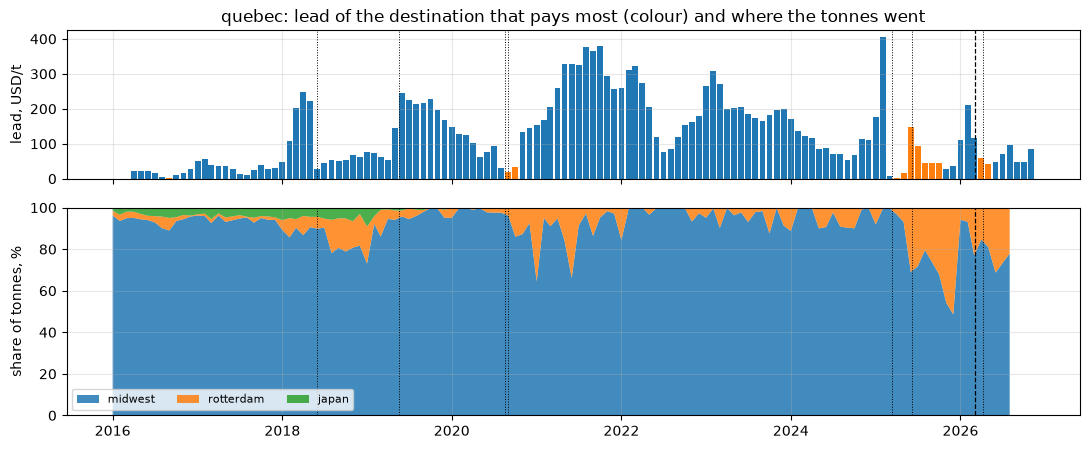

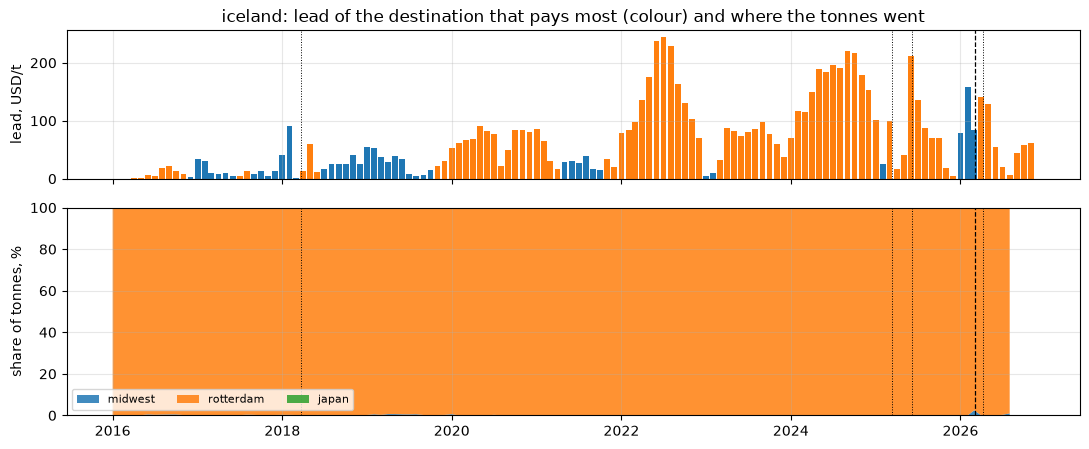

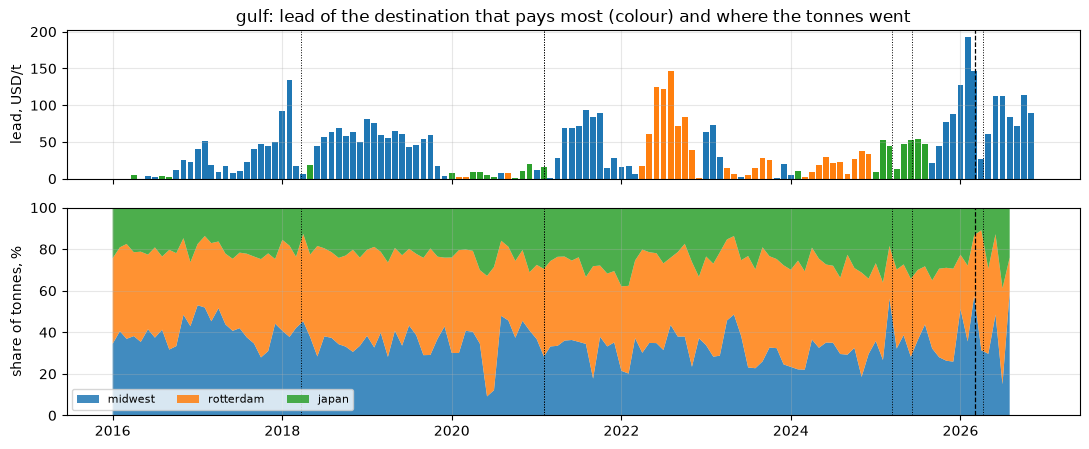

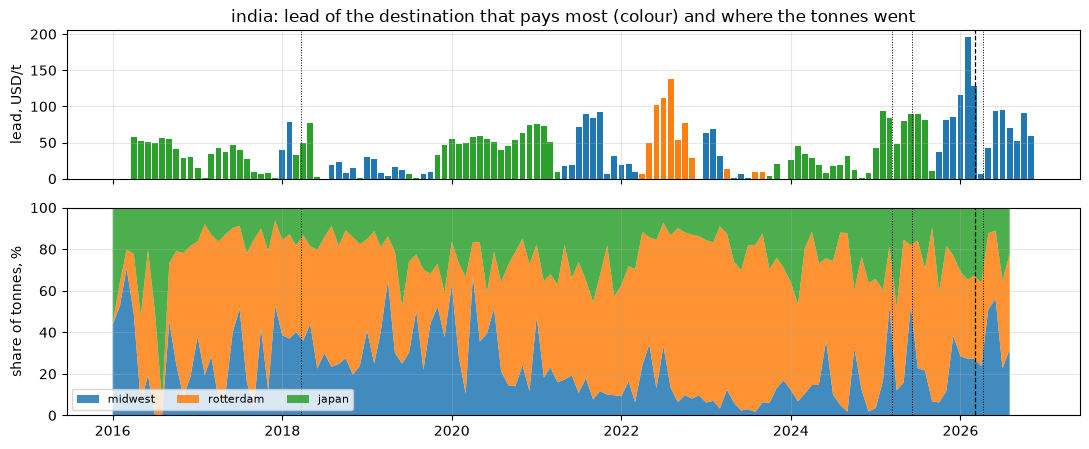

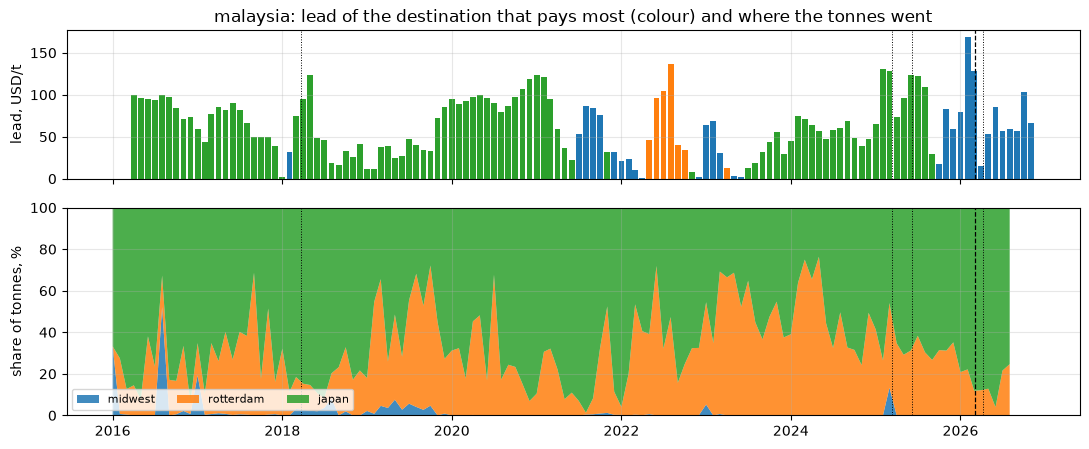

In [9]:
# Hormuz is on no route, the Gulf origin loads outside it: its container transits, a week at a time, against 2019
h = sql.query(f"SELECT date, {c.TRANSITS} AS ships FROM transits WHERE portname = 'Strait of Hormuz' ORDER BY date")
h = h.set_index(pd.to_datetime(h["date"]))["ships"]
hormuz = h.rolling("7D").mean() / h.loc["2019"].mean()
closed = hormuz.loc["2026":][hormuz.loc["2026":] < 0.5].index.min()
print(f"Hormuz under half its 2019 traffic from the week to {closed:%d %B %Y}")
tariffs = sql.query("SELECT origin_group, effective, rate FROM tariffs WHERE effective > DATE '2016-01-01'")
start = shares.index.get_level_values("period").min()
for origin in ORIGINS:
    s = shares.loc[origin]
    sig = signal.loc[origin].loc[start:]
    fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, height_ratios=[1, 1.4])
    axes[0].bar(sig.index, sig["lead"], width=25, color=sig["winner"].map(COLORS))
    axes[0].set_ylabel("lead, USD/t"); axes[0].set_title(f"{origin}: lead of the destination that pays most (colour) and where the tonnes went")
    axes[1].stackplot(s.index, *[s[d] for d in DESTINATIONS], colors=[COLORS[d] for d in DESTINATIONS], labels=DESTINATIONS, alpha=.85)
    axes[1].set_ylabel("share of tonnes, %"); axes[1].set_ylim(0, 100); axes[1].legend(loc="lower left", ncols=3, fontsize=8)
    for date in tariffs[tariffs["origin_group"] == c.ORIGINS[origin]["tariff"]]["effective"]:
        for ax in axes:
            ax.axvline(date, color="k", lw=.7, ls=":")
    for ax in axes:
        ax.axvline(closed, color="k", lw=.9, ls="--")
    plt.tight_layout()
    plt.show()

- **Quebec ships to the US, and turned to Europe once.** Over 85% of its tonnes go to the US in almost every month; the exception is 2025, when the Rotterdam bars appear in the lead panel and Europe's share of the tonnes rises to between 20 and 50%.
- **Iceland ships to Europe, all of it.** 99.9% of its tonnes go to the EU-27 whatever the netback says: Iceland's metal is sold under long-term contracts into Europe, and the Midwest leads are never acted on.
- **The Gulf splits its tonnes and keeps the split.** About a third to each destination, with little response to which one pays most: the pattern of term contracts with customers in all three markets.
- **India and Malaysia move more.** India's European share rose to 60 to 80% with Rotterdam's leads of 2022 and stayed there for two years after they ended; Malaysia ships to Japan and Europe and almost never to the US, even when the Midwest paid most from late 2025.

## 5. Three episodes

**The tariff doubled on 4 June 2025.** What the netback said in the months around it, and what the tonnes did.

In [10]:
months = slice("2025-02", "2025-12")
episode = pd.concat({o: pd.concat([signal.loc[o].loc[months, ["winner", "lead"]], shares.loc[o].loc[months, DESTINATIONS + ["tonnes"]]], axis=1) for o in ["gulf", "india", "malaysia"]})
episode

winner  lead  midwest  rotterdam  japan    tonnes
         period                                                        
gulf     2025-02-01    japan  52.7     26.7       37.3   36.1 122,243.1
         2025-03-01    japan  44.3     56.3       25.3   18.5 167,305.5
         2025-04-01    japan  13.2     32.2       38.0   29.8 129,299.5
         2025-05-01    japan  47.1     38.6       34.0   27.3 161,103.3
         2025-06-01    japan  52.0     28.2       37.6   34.3 124,189.3
         2025-07-01    japan  54.6     36.3       33.8   30.0 116,440.8
         2025-08-01    japan  46.6     43.8       27.9   28.3 124,773.4
         2025-09-01  midwest  20.7     32.2       32.8   35.0 106,546.2
         2025-10-01  midwest  44.8     28.0       42.6   29.4 122,522.6
         2025-11-01  midwest  77.5     26.3       44.7   29.0  94,924.6
         2025-12-01  midwest  87.5     25.9       44.7   29.4 118,432.5
india    2025-02-01    japan  93.5     16.7       43.6   39.7  34,763.6
         2025-03-01    japan  84.6     52.4       28.9   18.6  57,643.7
         2025-04-01    japan  48.6     12.0       40.0   48.0  36,139.5
         2025-05-01    japan  79.4     15.8       68.7   15.5  37,544.1
         2025-06-01    japan  89.0     52.9       29.0   18.1  73,475.9
         2025-07-01    japan  89.0     22.7       61.4   15.8  31,307.1
         2025-08-01    japan  80.6     21.6       49.1   29.4  39,668.2
         2025-09-01    japan  10.3      6.7       83.8    9.5  32,547.6
         2025-10-01  midwest  37.2      6.3       53.4   40.3  39,389.1
         2025-11-01  midwest  81.4     11.6       70.0   18.4  30,287.6
         2025-12-01  midwest  85.5     38.3       38.7   23.0  70,262.3
malaysia 2025-02-01    japan 131.0      0.0       26.5   73.5  20,952.0
         2025-03-01    japan 128.1     13.3       40.8   45.9  25,751.0
         2025-04-01    japan  73.8      0.0       34.7   65.3  28,648.5
         2025-05-01    japan  96.6      0.0       29.2   70.8  27,583.4
         2025-06-01    japan 124.1      0.0       31.2   68.8  17,120.9
         2025-07-01    japan 122.4      0.0       38.3   61.7  20,368.2
         2025-08-01    japan 108.8      0.0       30.4   69.6  22,344.1
         2025-09-01    japan  29.8      0.0       26.7   73.3  25,754.3
         2025-10-01  midwest  17.5      0.0       31.4   68.6  32,178.6
         2025-11-01  midwest  82.8      0.0       31.2   68.8  26,632.9
         2025-12-01  midwest  59.0      0.0       35.2   64.8  22,005.2

- **The netback said Japan until August 2025, the Midwest from September.** With the duty at 50% from 4 June, the Midwest premium took three months to more than refund it (notebook 02, section 6); until then the eastern origins netted back more in Japan.
- **The tonnes moved before.** The Gulf sent 56% of its tonnes to the US in March 2025 and India 52% in March and 53% in June: the months the duty rose, as metal landed ahead of the increase. After June the US share fell back for both.
- **Malaysia never went.** From October 2025 the Midwest paid Malaysia most by 17 to 83 USD/t, and its US share stayed at zero: Malaysian metal is placed in Japan and Europe.

**Quebec turns to Europe in the spring of 2025.** Canada's own export statistics, by quarter: the share of its exports of unwrought aluminium that went to the EU-27.

In [11]:
canada = sql.query("SELECT partner, period, tonnes, first_released FROM flows WHERE reporter = 'canada_exports'")
canada["partner"] = canada["partner"].astype(int)
# November 2025 has no weight for the US, Canada's main customer (notebook 01): the month is left out
unweighed = canada.loc[(canada["partner"] == 842) & canada["tonnes"].isna(), "period"]
canada = canada[~canada["period"].isin(unweighed)]
quarter = canada["period"].dt.to_period("Q")
# the total is the sum of the partners: Comtrade has no World row for November 2025
partners = canada["partner"] != 0
world = canada[partners].groupby(quarter[partners])["tonnes"].sum()
europe = canada[canada["partner"].isin(c.EU27)].groupby(quarter[canada["partner"].isin(c.EU27)])["tonnes"].sum()
us = canada[canada["partner"] == 842].groupby(quarter[canada["partner"] == 842])["tonnes"].sum()
quebec = pd.DataFrame({"months": canada.groupby(quarter)["period"].nunique(), "exports, kt": world / 1000,
                       "to the EU-27, %": 100 * europe / world, "to the US, %": 100 * us / world}).loc["2024Q1":]
quebec["netback winner, share of days"] = [", ".join(f"{d} {100 * v:.0f}%" for d, v in nb[(nb["origin"] == "quebec")].pivot_table(index="trade_date", columns="destination", values="netback").pipe(lambda w: w.loc[w.index.to_period("Q") == q].idxmax(axis=1).value_counts(normalize=True)).items()) for q in quebec.index]
quebec

,months,"exports, kt","to the EU-27, %","to the US, %","netback winner, share of days"
period,,,,,
2024Q1,3,779.5,5.8,92.7,midwest 100%
2024Q2,3,722.1,2.9,94.1,midwest 100%
2024Q3,3,745.1,0.1,92.0,midwest 100%
2024Q4,3,685.0,0.2,96.1,midwest 100%
2025Q1,3,721.4,0.2,97.1,"midwest 70%, rotterdam 30%"
2025Q2,3,600.0,12.6,80.3,"rotterdam 75%, midwest 25%"
2025Q3,3,561.1,20.1,68.8,rotterdam 100%
2025Q4,2,452.4,27.3,68.2,"midwest 56%, rotterdam 44%"
2026Q1,3,579.2,15.3,81.4,"midwest 98%, rotterdam 2%"


- **The share of Canada's exports going to the EU-27 rose from 0.2% to 13% between the first and second quarters of 2025, to 20% in the third and 27% in the fourth**, while the US share fell from 97% to 68%. The fourth quarter counts October and December only: November has no weight for the US. The netback put Rotterdam first on 75% of the trade dates of the second quarter and on all of the third.
- **The tonnes followed with about a quarter's delay.** The netback turned to Rotterdam with the 25% duty in mid-March; the European share rose from April and peaked in the fourth quarter, when the netback had already swung back to the Midwest on most days.
- **The brief's 18% is Quebec's own figure.** These are Canada's: they include British Columbia, whose metal goes to the US and Asia, so the European share of Quebec's metal is higher than Canada's.
- **It did not reverse fully.** Since 2026 Europe takes 14 to 15% of Canada's exports, against near zero before 2025, with the Midwest back on top on most days, and the Rotterdam lead of the second quarter of 2026 did not raise it: once placed, the European customers kept part of the metal, and a short lead was not enough to send more.

**Hormuz closes in March 2026.** PortWatch's container transits at Hormuz against the Gulf's shipments to the three destinations and what the netback said.

In [12]:
gulf = pd.concat([signal.loc["gulf"].loc["2025-09":, ["winner", "lead"]], shares.loc["gulf"].loc["2025-09":, DESTINATIONS + ["tonnes"]]], axis=1)
gulf["Hormuz transits vs 2019"] = hormuz.resample("MS").mean().reindex(gulf.index)
gulf

,winner,lead,midwest,rotterdam,japan,tonnes,Hormuz transits vs 2019
period,,,,,,,
2025-09-01,midwest,20.7,32.2,32.8,35.0,"106,546.2",1.6
2025-10-01,midwest,44.8,28.0,42.6,29.4,"122,522.6",1.7
2025-11-01,midwest,77.5,26.3,44.7,29.0,"94,924.6",1.2
2025-12-01,midwest,87.5,25.9,44.7,29.4,"118,432.5",0.9
2026-01-01,midwest,127.4,51.2,26.1,22.7,"145,271.2",1.0
2026-02-01,midwest,192.3,35.6,36.5,27.9,"105,993.9",1.3
2026-03-01,midwest,146.2,57.6,29.1,13.2,"206,418.9",0.1
2026-04-01,midwest,26.4,31.3,57.8,10.9,"68,367.2",0.1
2026-05-01,midwest,60.8,29.6,41.0,29.3,"62,285.0",0.0


- **The closure shows in the tonnes from April 2026.** Transits at Hormuz fell to a tenth of 2019 in March; the Gulf's shipments to the three destinations, a record 206 kt in March as cargoes already loaded landed, fell to 62 to 74 kt a month from April to July and recovered to 100 kt in August as EGA moved exports to Khor Fakkan and Sohar.
- **The netback never stopped saying the Midwest.** The netback prices a cargo loaded at Khor Fakkan, outside the strait; the metal smelted inside it had first to reach the port. What fell was the volume, not its direction: the US share stayed between 15 and 59%.
- **The episode is a limit of the method, not a failure.** A netback says where a tonne should go once it is on the ship; it says nothing about whether it can get there.

## 6. Agreement table and lag

In [13]:
summary = pd.DataFrame({k: {"months": table[f"agree_{k}"].notna().sum(), "agree": table[f"agree_{k}"].sum(),
                            "agree, %": 100 * table[f"agree_{k}"].sum() / table[f"agree_{k}"].notna().sum()} for k in lags}).T
summary.index.name = "lag, months"
summary

,months,agree,"agree, %"
"lag, months",,,
1,620.0,214.0,34.5
2,615.0,226.0,36.7
3,610.0,232.0,38.0


In [14]:
# by origin and lag, in %
pd.DataFrame({k: 100 * table.groupby("origin")[f"agree_{k}"].mean() for k in lags}).loc[ORIGINS]

,1,2,3
origin,,,
quebec,46.8,52.0,51.6
iceland,31.5,33.3,36.9
gulf,27.4,31.7,30.3
india,25.0,28.5,31.1
malaysia,41.9,38.2,40.2


In [15]:
retained = summary["agree, %"].idxmax()
# the level: each destination's share of an origin's tonnes, at the retained lag, in the months it paid most and in the others
level = []
for origin in ORIGINS:
    later = shares.loc[origin][DESTINATIONS].shift(-retained)
    winner = signal.loc[origin]["winner"].reindex(later.index)
    for d in DESTINATIONS:
        level.append({"origin": origin, "destination": d, "months it paid most": (winner == d).sum(),
                      "share when it paid most, %": later.loc[winner == d, d].mean(), "share otherwise, %": later.loc[winner != d, d].mean()})
level = pd.DataFrame(level).set_index(["origin", "destination"])
# a destination that never paid most cannot be compared
level["higher when it paid most"] = (level["share when it paid most, %"] > level["share otherwise, %"]).where(level["months it paid most"] > 0)
print(f"retained lag: {retained} months")
level

retained lag: 3 months


months it paid most  share when it paid most, %  share otherwise, % higher when it paid most
origin   destination                                                                                              
quebec   midwest                      113                        92.7                78.5                     True
         rotterdam                     12                        25.2                 5.8                     True
         japan                          0                         NaN                 1.3                      NaN
iceland  midwest                       42                         0.2                 0.1                     True
         rotterdam                     83                        99.9                99.8                     True
         japan                          0                         NaN                 0.0                      NaN
gulf     midwest                       75                        36.5                33.4                     True
         rotterdam                     28                        41.6                40.3                     True
         japan                         22                        25.7                23.9                     True
india    midwest                       44                        24.7                22.1                     True
         rotterdam                     12                        74.0                51.4                     True
         japan                         69                        24.1                22.7                     True
malaysia midwest                       27                         0.3                 1.6                    False
         rotterdam                      7                        38.0                31.6                     True
         japan                         91                        67.0                66.1                     True

In [16]:
# the months where the netback lead was large: does the agreement improve when the signal is strong?
strong = table["lead"] > table["lead"].median()
pd.DataFrame({"lead above the median": 100 * table.loc[strong, f"agree_{retained}"].mean(),
              "lead below the median": 100 * table.loc[~strong, f"agree_{retained}"].mean()}, index=[f"agree at {retained} months, %"])

,lead above the median,lead below the median
"agree at 3 months, %",37.3,38.7


- **At the count of the brief, nothing beats chance by much.** 35 to 38% of months agree, against 33% for chance. Quebec does best, 52% at two months; India and the Gulf do worst, 25 to 32%.
- **Three months is the lag retained, by the rule of the brief: the lag with most agreements.** The margin over two months is 1.3 points, ten months out of 610: the count does not really pick a lag.
- **The level tells more than the direction.** In 12 of the 13 pairs that can be compared a destination takes a larger share three months after the months it paid most. Most of the differences are one to three points, Iceland's a tenth of one. Four are large: 93% of Quebec's tonnes go to the US after the months the Midwest paid most against 78% otherwise, 25% to Europe against 6%, 74% of India's to Europe against 51%, 38% of Malaysia's against 32%. Malaysia's US share is the one exception.
- **A larger lead does not help.** Months whose lead is above the median agree no more often than the others: what moves the tonnes is a regime that lasts, not one month's gap.

## 7. When the tonnes go the other way

Every month whose agreement at the retained lag fails, with the most likely explanation. The explanations are rules, written here and applied in order, and the last is "unexplained":

1. **within the freight band**: the lead is smaller than the change freight ±30% makes to it (notebook 02, section 7), so the netback cannot tell the two destinations apart;
2. **one destination takes everything**: over the twelve months before, one destination took more than 90% of the origin's tonnes, the mark of annual contracts or of a single customer;
3. **too few tonnes to read**: under 5,000 t a month shipped to the three;
4. **revised**: one of the two months has more than one release on file;
5. **unexplained**.

In [17]:
low = flows.signal(netback.table(freight_scale=0.7))
high = flows.signal(netback.table(freight_scale=1.3))
contrary = table[table[f"agree_{retained}"] == False].set_index(["origin", "period"])
contrary = contrary[["winner", "lead", f"rose_{retained}"]].rename(columns={f"rose_{retained}": "share rose most"})
vintages = flows.shipments().groupby(["origin", "period"])["vintages"].max()
dominant = shares[DESTINATIONS].groupby(level="origin").transform(lambda x: x.rolling(12).mean().shift(1)).max(axis=1)
reasons = []
for (origin, period), row in contrary.iterrows():
    later = period + pd.DateOffset(months=retained)
    if low.loc[(origin, period), "winner"] != row["winner"] or high.loc[(origin, period), "winner"] != row["winner"]:
        reasons.append("within the freight band")
    elif dominant.get((origin, period), 0) > 90:
        reasons.append("one destination takes everything")
    elif shares.loc[(origin, period), "tonnes"] < 5000 or shares.loc[(origin, later), "tonnes"] < 5000:
        reasons.append("too few tonnes to read")
    elif vintages.get((origin, period), 1) > 1 or vintages.get((origin, later), 1) > 1:
        reasons.append("revised")
    else:
        reasons.append("unexplained")
contrary["most likely"] = reasons
contrary["most likely"].groupby(level="origin").value_counts().unstack().fillna(0).astype(int).loc[[o for o in ORIGINS if o in contrary.index.get_level_values("origin")]]

most likely,one destination takes everything,too few tonnes to read,unexplained,within the freight band
origin,,,,
quebec,43,0,13,3
iceland,73,0,0,4
gulf,0,0,69,16
india,0,2,55,27
malaysia,0,11,45,17


In [18]:
# every month against the netback, by origin and explanation
for (origin, reason), months in contrary.reset_index().groupby(["origin", "most likely"])["period"]:
    print(f"{origin}, {reason} ({len(months)}):")
    print(textwrap.fill(", ".join(months.dt.strftime("%Y-%m")), 120, initial_indent="    ", subsequent_indent="    "))

gulf, unexplained (69):
    2016-12, 2017-01, 2017-02, 2017-03, 2017-04, 2017-05, 2017-07, 2017-08, 2017-12, 2018-02, 2018-03, 2018-04, 2018-05,
    2018-07, 2018-08, 2018-09, 2019-01, 2019-03, 2019-05, 2019-06, 2019-07, 2019-08, 2019-10, 2019-11, 2020-01, 2020-02,
    2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09, 2020-12, 2021-01, 2021-02, 2021-05, 2021-06, 2021-07, 2021-08,
    2021-10, 2021-11, 2021-12, 2022-01, 2022-03, 2022-04, 2022-05, 2022-06, 2022-07, 2022-09, 2022-10, 2022-11, 2023-05,
    2023-08, 2023-09, 2023-10, 2023-12, 2024-10, 2024-11, 2024-12, 2025-02, 2025-05, 2025-06, 2025-07, 2025-08, 2025-09,
    2026-01, 2026-02, 2026-03, 2026-04
gulf, within the freight band (16):
    2016-04, 2016-06, 2016-07, 2016-08, 2016-09, 2017-06, 2019-12, 2023-06, 2023-07, 2023-11, 2024-02, 2024-03, 2024-04,
    2024-05, 2024-09, 2025-04
iceland, one destination takes everything (73):
    2017-09, 2017-12, 2018-01, 2018-02, 2018-05, 2018-07, 2018-09, 2019-04, 2019-05, 2019-06, 201

- **Structure explains a third of the disagreements.** Iceland and Quebec send over 90% of their tonnes to one country year after year: when their share elsewhere rises by a point it is noise, not a choice.
- **Freight explains another sixth.** In 67 months the lead of the winner is smaller than what freight ±30% does to it: the netback cannot tell the two destinations apart.
- **182 months stay unexplained, almost all from the Gulf, India and Malaysia.** Those origins split their tonnes across the three destinations under term contracts and move them for reasons a spot netback does not see: contract timing, a customer's plant, a ship's schedule. Labelling them would be guessing.
- **No month is explained by a revision yet**: the files hold one download. The rule is in place for the next ones.

## 8. Limitations

- **Importers' declarations at country level.** The EU stands for Rotterdam and the United States for the Midwest; a tonne declared in Hamburg or Los Angeles counts the same. The Gulf is the UAE and Oman, Quebec is Canada.
- **Customs months, not loading months.** A tonne counts in the month it is declared at arrival, three to six weeks after it was sold on the netback: part of every lag is the voyage.
- **Late and revised.** One to three months late, and revised by the sources; one download on file, so revisions are counted from the next one on.
- **Annual contracts.** Most primary aluminium moves under annual contracts with set destinations: the statistics count all of it, the netback prices the next spot tonne.
- **A count, not a test.** 610 origin-months, no regression and no test statistic, as the brief asks. The level comparison is a difference of means on overlapping months, read, not tested.
- **Small samples where it matters.** Rotterdam paid Quebec most in 12 months and India in 12: the strongest results rest on a handful of months.